# PROJECT TITLE 

# TITLE : TRAIN ROUTE ANALYSIS AND JOURNEY TIME PREDICTION.

#### This project focuses on applying Data Science Techniques to analyze train journey data and build a predictive model for estimating train journey       duration.
### OBJECTIVE 
#### 1.Understand and clean real-world transportation data.
#### 2.Perform exploratory data analysis and visualization.
#### 3.Identify patterns and relationships in journey data.
#### 4.Build and evaluate a predictive machine learning model.
#### 5.Present insights in a structured and professional manner.

# IMPORTING LIBRARIES 

## The required Python libraries are imported for data manipulation,numerical computation, visualization, and machine learning model     development.
#### 1.It makes our work much easier, there's no need to code from scratch. 
#### 2.There are different types of Python libraries available to work with our data in this we are using certain libraries like...
#### -> PANDAS - its one of the libraries used for data handling and analysis.
#### -> NUMPY- its used to handle numerical operations performed in the project.
#### -> MATPLOTLIB.PYPLOT  - its used to create basic graphs for data visualization purpose.
#### -> SEABORN - it is built on top of matplotlib library. its used to create most attractive statistical graphs.
#### -> SKLEARN - 
####   1. its mainly derived as "scikit-learn" library, it's one of the machine learning algorithms used for prediction. 
####   2. its mainly used to work with ready-made machine learning algorithms.
####   3. In this project we used "LINEAR REGRESSION ALGORITHM" from supervised machine learning algorithms for prediction purpose.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import sklearn 

# LOAD DATASET

## Loading Dataset:
#### 1.The dataset contains railway train route information of different stations.
#### 2.pandas as "pd" which is an alias name for pandas library which is used to load the given data set. 
#### 3."read_csv" its a pandas function , csv(comma separated values) it stores the data in rows and columns format which is further represented in            table format,for better understanding of data.
#### 4.pandas reads the provided file and converts it into a "DataFrame" which is nothing but into an table format with rows and columns. 
#### 5."df" is an variable name given to call a function. 
#### 6."pd.read_csv" is an function name and ("Dataset1.csv") is an argument given to function, to perform its given task.

In [2]:
df = pd.read_csv("Dataset1.csv")

#  LEVEL-1 : DATA OVERVIEW

## TASK 1.1: DATASET SUMMARY


#### 1.This step is used to understand structure of data set, including total records,columns and Datatypes.
#### 2.The below codes are used to understand the given data .
#### 3."df.head()" - It Displays the first '5' rows.
#### 4."df.shape" - It displays total no.of rows and columns.
#### 5."df.info()" - It gives information with column names, Non-Null Count, Data types .   

In [3]:
df.head()

,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance
0,1,107,SWV,100,100,100,100,SAWANTWADI R,1,00:00:00,10:25:00,0
1,2,107,THVM,260,228,196,164,THIVIM,1,11:06:00,11:08:00,32
2,3,107,KRMI,345,296,247,198,KARMALI,1,11:28:00,11:30:00,49
3,4,107,MAO,490,412,334,256,MADGOAN JN.,1,12:10:00,00:00:00,78
4,1,108,MAO,100,100,100,100,MADGOAN JN.,1,00:00:00,20:30:00,0


In [4]:
df.shape

(186074, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186074 entries, 0 to 186073
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   SN              186074 non-null  int64 
 1   Train_No        186074 non-null  int64 
 2   Station_Code    186074 non-null  object
 3   1A              186074 non-null  int64 
 4   2A              186074 non-null  int64 
 5   3A              186074 non-null  int64 
 6   SL              186074 non-null  int64 
 7   Station_Name    186074 non-null  object
 8   Route_Number    186074 non-null  int64 
 9   Arrival_time    186074 non-null  object
 10  Departure_Time  186074 non-null  object
 11  Distance        186074 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 17.0+ MB


In [6]:
df.isnull().sum()

SN                0
Train_No          0
Station_Code      0
1A                0
2A                0
3A                0
SL                0
Station_Name      0
Route_Number      0
Arrival_time      0
Departure_Time    0
Distance          0
dtype: int64

In [7]:
df.describe()

,SN,Train_No,1A,2A,3A,SL,Route_Number,Distance
count,186074.000000,186074.000000,186074.000000,186074.000000,186074.000000,186074.000000,186074.0,186074.000000
mean,13.914695,42157.747455,1506.769189,1225.415351,944.061513,662.735777,1.0,281.353838
std,12.779368,25090.080221,2418.719821,1934.975856,1451.231892,967.524012,0.0,483.743964
min,1.000000,107.000000,100.000000,100.000000,100.000000,100.000000,1.0,0.000000
25%,5.000000,17225.000000,215.000000,192.000000,169.000000,146.000000,1.0,23.000000
50%,11.000000,40050.000000,465.000000,392.000000,319.000000,246.000000,1.0,73.000000
75%,18.000000,57550.000000,1555.000000,1264.000000,973.000000,682.000000,1.0,291.000000
max,118.000000,99908.000000,21400.000000,17140.000000,12880.000000,8620.000000,1.0,4260.000000


## TASK 1.2: TRAIN WISE ROUTE TABLE 


## Train-wise Route Summary based on below code :

#### 1. A single train contains multiple station records.
#### 2. groupby() is used to combine all records belonging to the same train.
#### 3. Aggregation is performed to identify:
#### 4. Start Station:
   #### --> First station visited by the train.
#### 5. End Station:
   #### -->Last station visited by the train.

In [8]:
route_summary = df.groupby("Train_No").agg(
Start_Station=("Station_Name","first"), 
End_Station=("Station_Name","last")
)
route_summary.head()

,Start_Station,End_Station
Train_No,,
107,SAWANTWADI R,MADGOAN JN.
108,MADGOAN JN.,SAWANTWADI R
128,MADGOAN JN.,CHHATRAPATI
290,DELHI-SAFDAR,DELHI-SAFDAR
401,AURANGABAD,VARANASI JN.


## TASK 1.3 : BASIC STATICS 



## Statistical Summary

#### 1. describe() provides statistical information:
   #### -> Mean
   #### -> Minimum
   #### -> Maximum
   #### -> Standard deviation
   #### -> Quartiles
#### 2. This helps understand distance, stops, and journey duration patterns.

## TASK 1.4 :MISSING VALUES

# Missing Value Analysis :

#### 1. Missing values can negatively affect analysis and machine learning models.
#### 2. "isnull()" identifies empty values.
#### 3. "sum()" counts the total missing values in each column.
#### 4. The dataset contains zero missing values, therefore no missing value treatment is required.

In [9]:
df.isnull().sum()

SN                0
Train_No          0
Station_Code      0
1A                0
2A                0
3A                0
SL                0
Station_Name      0
Route_Number      0
Arrival_time      0
Departure_Time    0
Distance          0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
route_summary = df.groupby("Train_No").agg(
Start_Station=("Station_Name","first"), 
End_Station=("Station_Name","last")
)
route_summary.head(10)

,Start_Station,End_Station
Train_No,,
107,SAWANTWADI R,MADGOAN JN.
108,MADGOAN JN.,SAWANTWADI R
128,MADGOAN JN.,CHHATRAPATI
290,DELHI-SAFDAR,DELHI-SAFDAR
401,AURANGABAD,VARANASI JN.
421,LUCKNOW JN.,SHRI MATA VA
422,SHRI MATA VA,LUCKNOW JN.
477,SIRSA,SIRSA
502,RAJENDRANAGA,AMBALA CANTT


In [12]:
df["Train_No"].nunique()

11113

# LEVEL-2 : DATA CLEANING & FEATURE ENGINEERING

## TASK 2.1: Handle Missing Values and Remove Duplicate Records

#### 1. Data cleaning is an important step in the Data Science workflow.
#### 2. Raw datasets may contain:
   #### -> Missing values
   #### -> Duplicate records
   #### -> Incorrect formats
   #### -> Inconsistent data
#### 3. Cleaning the dataset improves the quality of analysis and helps build better machine learning models.
#### 4.In this task, we check
  #### 1. Missing values
  #### 2. Duplicate records

### --> HANDLING MISSING VALUES : 

#### 1. We use "df.isnull().sum()" to work with missing values. as this step is already completed previously in "TASK 1.4" can proceed with removing             duplicate Records

### --> DUPLICATE CHECK :

#### 1. duplicated() identifies repeated rows in the dataset.
#### 2. sum() counts how many duplicate rows exist.
#### 3. The dataset contains no missing values and no duplicate records.
#### 4. Therefore, no additional treatment is required for missing values or duplicate removal.
#### 5.The dataset is ready for further preprocessing

In [13]:
df.duplicated().sum()

np.int64(0)

## TASK 2.2: STANDARDIZE ARRIVAL AND DEPARTURE TIME FORMATS


#### 1.The arrival and departure time columns are initially stored as text values.
#### 2.For performing calculations such as journey duration, time values must be converted into datetime format.
#### 3.Datetime format allows Python to:
  #### -> Compare times
  #### -> Perform time calculations
  #### -> Extract time-related features
#### 4.Arrival and departure time columns were successfully converted into datetime format in the below code .
#### 5.This allows calculation of journey duration in the next step.

In [14]:
df["Arrival_time"] = pd.to_datetime(df["Arrival_time"], format="%H:%M:%S")
df["Departure_Time"] = pd.to_datetime(df["Departure_Time"], format="%H:%M:%S")

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186074 entries, 0 to 186073
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   SN              186074 non-null  int64         
 1   Train_No        186074 non-null  int64         
 2   Station_Code    186074 non-null  object        
 3   1A              186074 non-null  int64         
 4   2A              186074 non-null  int64         
 5   3A              186074 non-null  int64         
 6   SL              186074 non-null  int64         
 7   Station_Name    186074 non-null  object        
 8   Route_Number    186074 non-null  int64         
 9   Arrival_time    186074 non-null  datetime64[ns]
 10  Departure_Time  186074 non-null  datetime64[ns]
 11  Distance        186074 non-null  int64         
dtypes: datetime64[ns](2), int64(8), object(2)
memory usage: 17.0+ MB


In [16]:
df[["Arrival_time","Departure_Time"]].head()

,Arrival_time,Departure_Time
0,1900-01-01 00:00:00,1900-01-01 10:25:00
1,1900-01-01 11:06:00,1900-01-01 11:08:00
2,1900-01-01 11:28:00,1900-01-01 11:30:00
3,1900-01-01 12:10:00,1900-01-01 00:00:00
4,1900-01-01 00:00:00,1900-01-01 20:30:00


## TASK 2.3: CALUCATION OF TOTAL JOURNEY DURATION OF EACH TRAIN 


#### 1.Journey duration represents the total travel time taken by a train from its starting station to the destination station.
#### 2.This feature is created by calculating the difference between:
   #### --> End Time - Start Time
#### 3.The calculated duration is converted into hours.
#### 4. IN THIS TASK :
   #### --> A new feature named "Journey_Duration" was created.
   #### --> This feature represents the total travel time of each train in hours.
   #### --> This feature will be used as the target variable for machine learning prediction.

## TASK 2.4: CREATE FEATURES SUCH AS TOTAL DISTANCE AND NUMBER OF STOPS


#### 1. Feature engineering is the process of creating new useful features from existing data.
#### 2. In this project, additional features are created in the below code as "Total_Distance=("Distance", "max")" and "Number_of_Stops=("SN", "max")"
   #### 1. Total Distance
   #### 2. Number of Stops
#### 3. These features help the machine learning model understand factors affecting journey duration.
#### 4. These features will be used as input variables for the prediction model.

In [17]:
journey_data = df.groupby("Train_No").agg(
    Start_Station=("Station_Name", "first"),
    End_Station=("Station_Name", "last"),
    Start_Time=("Departure_Time", "first"),
    End_Time=("Arrival_time", "last"),
    Total_Distance=("Distance", "max"),
    Number_of_Stops=("SN", "max")
)

journey_data.head()

,Start_Station,End_Station,Start_Time,End_Time,Total_Distance,Number_of_Stops
Train_No,,,,,,
107,SAWANTWADI R,MADGOAN JN.,1900-01-01 10:25:00,1900-01-01 12:10:00,78,4
108,MADGOAN JN.,SAWANTWADI R,1900-01-01 20:30:00,1900-01-01 22:25:00,83,4
128,MADGOAN JN.,CHHATRAPATI,1900-01-01 19:40:00,1900-01-01 17:45:00,978,22
290,DELHI-SAFDAR,DELHI-SAFDAR,1900-01-01 18:30:00,1900-01-01 02:30:00,2694,14
401,AURANGABAD,VARANASI JN.,1900-01-01 21:30:00,1900-01-01 10:00:00,1618,12


In [18]:
journey_data.describe()

,Start_Time,End_Time,Total_Distance,Number_of_Stops
count,11113,11113,11113.000000,11113.000000
mean,1900-01-01 13:17:37.933951488,1900-01-01 13:44:35.812111872,348.870242,16.746963
min,1900-01-01 00:01:00,1900-01-01 00:00:00,1.000000,2.000000
25%,1900-01-01 08:08:00,1900-01-01 09:10:00,38.000000,8.000000
50%,1900-01-01 13:40:00,1900-01-01 13:25:00,82.000000,15.000000
75%,1900-01-01 18:05:00,1900-01-01 19:00:00,324.000000,22.000000
max,1900-01-01 23:59:00,1900-01-01 23:59:00,4260.000000,118.000000
std,NaN,NaN,596.179751,12.995127


In [19]:
journey_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11113 entries, 107 to 99908
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Start_Station    11113 non-null  object        
 1   End_Station      11113 non-null  object        
 2   Start_Time       11113 non-null  datetime64[ns]
 3   End_Time         11113 non-null  datetime64[ns]
 4   Total_Distance   11113 non-null  int64         
 5   Number_of_Stops  11113 non-null  int64         
dtypes: datetime64[ns](2), int64(2), object(2)
memory usage: 607.7+ KB


In [20]:
journey_data.shape

(11113, 6)

In [21]:
journey_data.head(10)

,Start_Station,End_Station,Start_Time,End_Time,Total_Distance,Number_of_Stops
Train_No,,,,,,
107,SAWANTWADI R,MADGOAN JN.,1900-01-01 10:25:00,1900-01-01 12:10:00,78,4
108,MADGOAN JN.,SAWANTWADI R,1900-01-01 20:30:00,1900-01-01 22:25:00,83,4
128,MADGOAN JN.,CHHATRAPATI,1900-01-01 19:40:00,1900-01-01 17:45:00,978,22
290,DELHI-SAFDAR,DELHI-SAFDAR,1900-01-01 18:30:00,1900-01-01 02:30:00,2694,14
401,AURANGABAD,VARANASI JN.,1900-01-01 21:30:00,1900-01-01 10:00:00,1618,12
421,LUCKNOW JN.,SHRI MATA VA,1900-01-01 23:00:00,1900-01-01 08:00:00,1276,5
422,SHRI MATA VA,LUCKNOW JN.,1900-01-01 11:45:00,1900-01-01 14:30:00,1277,5
477,SIRSA,SIRSA,1900-01-01 12:10:00,1900-01-01 15:20:00,2616,14
502,RAJENDRANAGA,AMBALA CANTT,1900-01-01 10:30:00,1900-01-01 09:30:00,1206,9


In [22]:
journey_data["Journey_Duration"] = (
    journey_data["End_Time"] - journey_data["Start_Time"]
).dt.total_seconds() / 3600

In [23]:
journey_data["Journey_Duration"].head(10)

Train_No
107     1.750000
108     1.916667
128    -1.916667
290   -16.000000
401   -11.500000
421   -15.000000
422     2.750000
477     3.166667
502    -1.000000
504     1.000000
Name: Journey_Duration, dtype: float64

In [24]:
(journey_data["Journey_Duration"]<0).sum()

np.int64(1922)

In [25]:
journey_data.loc[
    journey_data["Journey_Duration"] < 0,
    "Journey_Duration"
] += 24

In [26]:
(journey_data["Journey_Duration"]<0).sum()

np.int64(0)

In [27]:
journey_data["Journey_Duration"].describe()

count    11113.000000
mean         4.600225
std          5.352782
min          0.000000
25%          1.016667
50%          2.200000
75%          6.083333
max         23.916667
Name: Journey_Duration, dtype: float64

In [28]:
journey_data[journey_data["Journey_Duration"] ==0]

,Start_Station,End_Station,Start_Time,End_Time,Total_Distance,Number_of_Stops,Journey_Duration
Train_No,,,,,,,
12617,ERNAKULAM. J,HAZRAT NIZAM,1900-01-01 13:15:00,1900-01-01 13:15:00,2751,48,0.0
12851,BILASPUR JN.,CHENNAI CENT,1900-01-01 08:55:00,1900-01-01 08:55:00,1412,17,0.0
16318,SHRI MATA VA,KANNIYAKUMAR,1900-01-01 21:55:00,1900-01-01 21:55:00,3765,75,0.0
18233,INDORE BG,BILASPUR JN.,1900-01-01 17:15:00,1900-01-01 17:15:00,1008,72,0.0
18477,PURI,HARIDWAR JN,1900-01-01 20:55:00,1900-01-01 20:55:00,2347,76,0.0
22633,TRIVANDRUM C,HAZRAT NIZAM,1900-01-01 14:15:00,1900-01-01 14:15:00,2841,29,0.0


In [29]:
journey_data[journey_data["Journey_Duration"] == 0].shape

(6, 7)

In [30]:
journey_data = journey_data[journey_data["Journey_Duration"] > 0]

In [31]:
journey_data.shape

(11107, 7)

# LEVEL-3 : EXPLORATORY DATA ANALYSIS [EDA]

## TASK 3.1: ANALYZE JOURNEY DURATION ACROSS ROUTES 

###  Route Duration Analysis

#### 1. Exploratory Data Analysis (EDA) is performed to understand patterns and relationships in the dataset.

#### 2. In this step, journey durations are analyzed to identify:
####    -> Short journeys
####    -> Long journeys
####    -> Route variations
#### 3. The analysis identifies trains with the longest journey duration.
#### 4. Long-distance routes generally require more travel time.

In [32]:

journey_data.sort_values(
    by="Total_Distance",
    ascending=False
).head(10)

,Start_Station,End_Station,Start_Time,End_Time,Total_Distance,Number_of_Stops,Journey_Duration
Train_No,,,,,,,
15905,KANNIYAKUMAR,DIBRUGARH,1900-01-01 23:00:00,1900-01-01 06:40:00,4260,57,7.666667
15906,DIBRUGARH,KANNIYAKUMAR,1900-01-01 23:05:00,1900-01-01 09:50:00,4256,58,10.750000
2515,TRIVANDRUM C,SILCHAR,1900-01-01 00:05:00,1900-01-01 05:00:00,3939,58,4.916667
12515,TRIVANDRUM C,SILCHAR,1900-01-01 12:40:00,1900-01-01 17:15:00,3932,57,4.583333
12507,TRIVANDRUM C,SILCHAR,1900-01-01 16:55:00,1900-01-01 19:00:00,3932,58,2.083333
12516,SILCHAR,TRIVANDRUM C,1900-01-01 19:55:00,1900-01-01 22:40:00,3930,56,2.750000
12508,SILCHAR,TRIVANDRUM C,1900-01-01 19:55:00,1900-01-01 22:40:00,3930,56,2.750000
16317,KANNIYAKUMAR,SHRI MATA VA,1900-01-01 14:15:00,1900-01-01 15:20:00,3769,71,1.083333
16687,MANGALORE CE,SHRI MATA VA,1900-01-01 17:05:00,1900-01-01 15:20:00,3663,63,22.250000


In [33]:
journey_data.sort_values(
    by="Number_of_Stops",
    ascending=False
).head(10)

,Start_Station,End_Station,Start_Time,End_Time,Total_Distance,Number_of_Stops,Journey_Duration
Train_No,,,,,,,
53041,HOWRAH JN.,JAYNAGAR,1900-01-01 07:15:00,1900-01-01 12:35:00,718,118,5.333333
13007,HOWRAH JN.,SHRI GANGANA,1900-01-01 09:35:00,1900-01-01 07:00:00,1949,112,21.416667
13049,HOWRAH JN.,AMRITSAR JN.,1900-01-01 13:50:00,1900-01-01 10:20:00,1908,111,20.500000
58112,ITWARI JN.,TATANAGAR JN,1900-01-01 21:15:00,1900-01-01 00:05:00,883,109,2.833333
13008,SHRI GANGANA,HOWRAH JN.,1900-01-01 21:00:00,1900-01-01 19:30:00,1952,108,22.500000
53042,JAYNAGAR,HOWRAH JN.,1900-01-01 20:10:00,1900-01-01 23:00:00,718,107,2.833333
13050,AMRITSAR JN.,HOWRAH JN.,1900-01-01 18:10:00,1900-01-01 15:45:00,1909,106,21.583333
58111,TATANAGAR JN,ITWARI JN.,1900-01-01 06:30:00,1900-01-01 06:35:00,885,102,0.083333
19019,BANDRA TERMI,DEHRA DUN,1900-01-01 00:05:00,1900-01-01 17:35:00,1676,98,17.500000


## TASK 3.2: IDENTIFY STATIONS WITH HIGH AND LOW TRAIN TRAFFICS 

### ---> Train traffic analysis helps identify which stations are frequently visited by trains and which stations have lower train movement. The code is given in below cell.

#### 1. This analysis helps understand:
#### -> Busy railway stations
#### -> Less frequently visited stations
#### -> Distribution of train movement across stations
#### 2. The station traffic is calculated by counting the number of train records associated with each station.
#### 3. The station traffic analysis identifies the stations with maximum and minimum train movement.
#### 4. The top stations represent highly connected railway locations with frequent train operations.
#### 5. Stations with lower traffic indicate less frequently visited routes.
#### 6. This analysis helps understand railway connectivity patterns.


## TASK 3.3: ANALYZE RELATIONSHIP BETWEEN DISTANCE AND JOURNEY DISTANCE 

In [34]:
station_traffic = df["Station_Name"].value_counts()

station_traffic.head(10)

Station_Name
CST-MUMBAI      1027
KALYAN JN        828
THANE            796
SEALDAH          745
CHENNAI BEAC     738
HOWRAH JN.       699
DADAR            598
DUM DUM JN.      463
KURLA            462
TAMBARAM         434
Name: count, dtype: int64

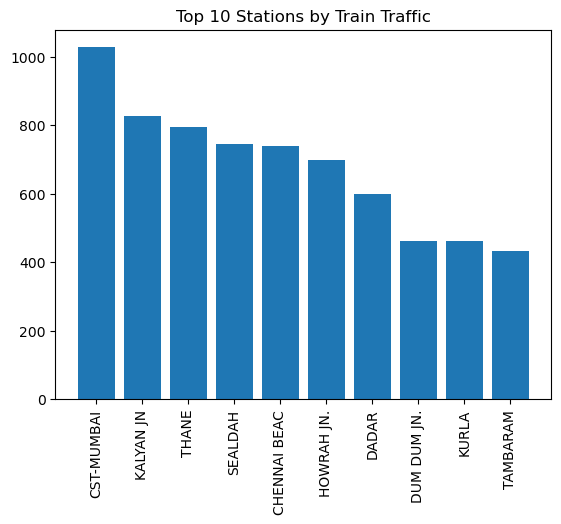

In [35]:
plt.bar(
station_traffic.head(10).index,
station_traffic.head(10).values
)

plt.xticks(rotation=90)

plt.title("Top 10 Stations by Train Traffic")

plt.show()

In [36]:
station_traffic.tail(10)

Station_Name
BARTARA  HAL       1
NATIONAL THE       1
RAMGHAT  HAL       1
BACHHARPUR H       1
AWAPUR F           1
NEW RUNNISAI       1
PARANUR            1
MANDAR VIDYA       1
PANJWARA ROA       1
SHMATA VD KATRA    1
Name: count, dtype: int64

### TASK 3.4: SUMMARIZE KEY EXPLORATORY  INSIGHTS

#### 1. After performing exploratory data analysis, important patterns and relationships are summarized.
#### 2. The purpose of this step is to convert analytical results into meaningful observations.
#### 3. The dataset contains railway route information including train numbers, stations, distance, and timings.
#### 4. Distance and journey duration have a positive relationship, meaning longer routes generally require more travel time.
#### 5. The number of stops also affects journey duration because trains with more stops take additional time.
#### 6. Some stations have higher train traffic compared to others, indicating important railway connections.
#### 7. Journey duration varies significantly depending on route distance and number of stops.
#### 8. The analysis helps identify patterns that can be used for predicting train journey duration.

# LEVEL-4 : DATA VISULAIZATION 

### TASK 4.1: VISUALIZATION OF JOURNEY DURATION ACROSS DIFFERENT ROUTES

#### 1. Visualization helps understand patterns in data using graphs.
#### 2. A histogram is created to analyze the distribution of journey duration.
#### It helps identify:
#### -> Common journey duration ranges
#### -> Short and long journeys

### TASK  4.2: CREATE CHARTS REPRESENTING STATION-WISE TRAIN TRAFFIC   

#### 1. Visualization helps to understand patterns in railway data.
#### 2. In this task, station-wise train traffic is visualized using a bar chart.
#### 3. The purpose of this analysis is to identify:
####    -> Stations with high train movement
####    -> Stations with low train movement
####    -> Important railway connectivity points
#### 4. The station traffic is calculated by counting the number of train records associated with each station.
#### 5. The station-wise traffic visualization shows the stations with the highest number of train movements.
#### 6. Highly connected stations have greater train traffic compared to smaller stations.
#### 7. This analysis helps identify important railway locations.

In [37]:
station_traffic = df["Station_Name"].value_counts()
top_stations = station_traffic.head(10)
top_stations

Station_Name
CST-MUMBAI      1027
KALYAN JN        828
THANE            796
SEALDAH          745
CHENNAI BEAC     738
HOWRAH JN.       699
DADAR            598
DUM DUM JN.      463
KURLA            462
TAMBARAM         434
Name: count, dtype: int64

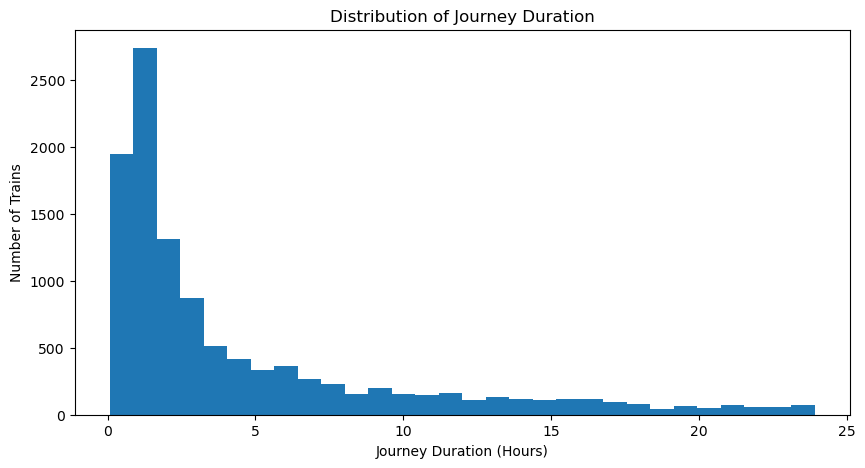

In [38]:
plt.figure(figsize=(10,5))

plt.hist(journey_data["Journey_Duration"], bins=30)

plt.title("Distribution of Journey Duration")
plt.xlabel("Journey Duration (Hours)")
plt.ylabel("Number of Trains")

plt.show()

In [39]:
journey_data[
    ["Total_Distance",
     "Number_of_Stops",
     "Journey_Duration"]
].corr()

,Total_Distance,Number_of_Stops,Journey_Duration
Total_Distance,1.000000,0.460139,0.639760
Number_of_Stops,0.460139,1.000000,0.503156
Journey_Duration,0.639760,0.503156,1.000000


# SCATTER PLOT 

## TASK 4.3: PLOT DISTANCE VS JOURNEY DURATION 

#### 1. A scatter plot is created to analyze the relationship between:
####     --> Total Distance
####     --> Journey Duration
#### 2. This helps understand whether longer distances require more travel time.
####  3. The visualization helps identify patterns and relationships between features.

#### 4. The scatter plot shows that journey duration generally increases as distance increases.
#### 5. Long-distance train routes require more travel time.
#### 6. However , some variations exist due to factors such as:
 #### -> Number of stops
 #### -> Route conditions
 #### -> Train schedules

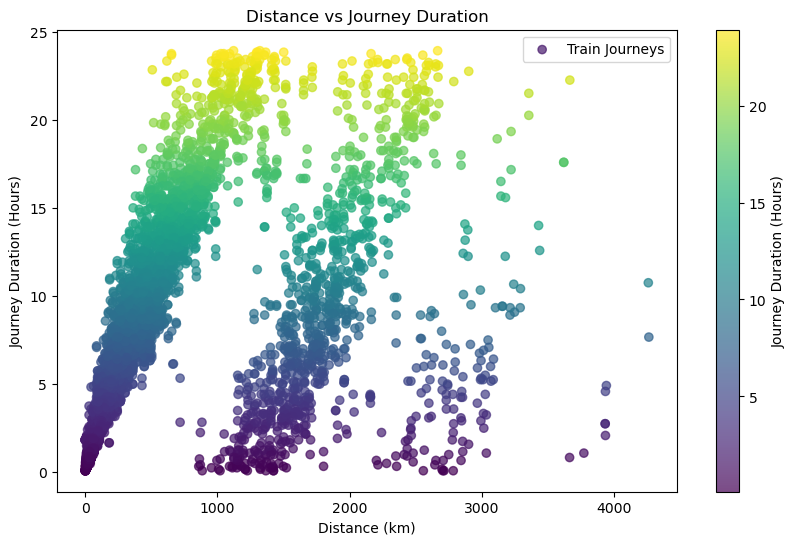

In [40]:
plt.figure(figsize=(10,6))
plt.scatter(
    journey_data["Total_Distance"],
    journey_data["Journey_Duration"],
    c=journey_data["Journey_Duration"],   # color based on duration
    cmap="viridis",
    alpha=0.7,
    label="Train Journeys"
)
plt.colorbar(
    label="Journey Duration (Hours)"
)
plt.title(
    "Distance vs Journey Duration"
)
plt.xlabel(
    "Distance (km)"
)
plt.ylabel(
    "Journey Duration (Hours)"
)
plt.legend()
plt.show()

## TASK 4.4: EXPLAIN PATTERNS OBSERVED FROM VISUAL ANALYSIS 

#### 1. After creating different visualizations, the observed patterns are analyzed.
#### 2. Visualization helps convert raw data into meaningful insights.

## --> Patterns Observed are

### 1. Journey Duration Distribution

#### -> The histogram shows that most trains have shorter journey durations, while fewer trains have very long journey durations.
#### -> This indicates that short and medium-distance routes are more common.
### 2. Station-wise Train Traffic
#### ->The station traffic chart shows that some stations have significantly higher train movement.
#### ->These stations act as major railway connectivity points.
### 3. Distance and Journey Duration Relationship
#### ->The scatter plot shows a positive relationship between distance and journey duration.
#### ->As the total distance increases, journey duration generally increases.
### 4. Factors Affecting Journey Duration
#### ->Journey duration depends on multiple factors:
#### ->> Total distance travelled
#### ->> Number of stops
#### ->> Route length
#### ->> Train schedule
#### ->> These observations help in selecting important features for machine learning prediction.

# CO-RELATION MATRIX

In [41]:
journey_data[
    ["Total_Distance",
     "Number_of_Stops",
     "Journey_Duration"]
].corr()

,Total_Distance,Number_of_Stops,Journey_Duration
Total_Distance,1.000000,0.460139,0.639760
Number_of_Stops,0.460139,1.000000,0.503156
Journey_Duration,0.639760,0.503156,1.000000


# LEVEL-5 : MACHINE LEARNING MODEL PREDICTION

## TASK 5.1: PREPARE A MODELIING DATASET USING DISTANCE AND NUMBER OF STOPS AS FEATURES. 

### 1. Machine learning models require:
###  --> Input variables (Features) and Output variable (Target)
### In this project:
### Features:
### ->> Total Distance
### ->> Number of Stops
### Target:
### ->> Journey Duration

In [42]:
x = journey_data[["Total_Distance" , "Number_of_Stops"]]
y = journey_data["Journey_Duration"]

print(x.shape)
print(y.shape)

(11107, 2)
(11107,)


## TASK 5.2 : SPLIT THE DATASET INTO TRAINING AND TESTING SETS 

#### Machine learning models should not be trained and tested on the same data.

### 1. If we use the same data for both training and testing:
### -> The model may memorize the data
### -> Performance evaluation will not be reliable
### 2.Therefore, the dataset is divided into:
### ->> 1. Training Data
   ### -> Used to train the machine learning model
   ### -> The model learns patterns from this data
   ### ->>2. Testing Data
   ### -> Used to evaluate the model performance
   ### -> Contains unseen data for prediction testing
### 3. In this project:
###   ->> Input Features:
### -> Total Distance
### -> Number of Stops
### Target Variable:
### -> Journey Duration
### 4. The dataset was successfully divided into training and testing sets.
### 5. 80% of the data is used for training the model and 20% is used for evaluating model performance.

In [43]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    )
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(8885, 2)
(2222, 2)
(8885,)
(2222,)


## TASK 5.3: BUILD A LINEAR REGRESSION MODEL TO PREDICT JOURNEY DURATION  

### 1. Linear Regression is a supervised machine learning algorithm.
### 2. It is used to predict continuous numerical values.
### 3. In this project, the model learns the relationship between:
   ### Input:
   #### -> Total Distance
   #### -> Number of Stops
   ### Output:
   #### -> Journey Duration
### 4. The objective is to predict how many hours a train journey will take based on route information.
### 5. The Linear Regression model was successfully trained using train data.
### 6. The model can now predict journey duration based on distance and number of stops.

In [44]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [45]:
y_pred = model.predict(x_test)

print(y_pred[:10])

[ 1.48734968  4.57881828 13.79811294  2.34865991  3.97825577  2.34865991
  1.98551983  2.13916368  5.62172069  2.4697103 ]


##  MODEL EVALUATION

### TASK 5.4 : EVALUATE MODEL EVALUTION USING "MAE" AND "RMSE"

#### 1. After building the model, its performance needs to be evaluated.
#### 2. Evaluation metrics measure how close the predicted values are to the actual values.
#### 3. This project uses:
#### ->  MAE (Mean Absolute Error)
#### -> RMSE (Root Mean Squared Error)
#### 4. The Linear Regression model was evaluated using MAE and RMSE metrics.
#### 5. The evaluation results show the average prediction error of the model.
#### 6. Lower error values indicate better prediction performance.
#### 7. The model successfully predicts train journey duration based on distance and number of stops.

In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 2.5180095033689134
RMSE: 15.213766164903285
R2 Score: 0.4445961969772969


##### LEVEL 6 : FINAL DATASCIENCE PROJECT 

### TASK 6.1:  DEVELOP A JOURNEY TIME PREDICTION SYSTEM USING LINEAR REGRESSION AND VISUALIZE ACTUAL VS PREDICTED JOURNEY DURATION . 

### 1. In this final stage, the trained Linear Regression model is integrated into a prediction system.
### 2. The system uses train route information to predict the expected journey duration.
### 3. The prediction system takes:
###     ->> Input Features:
####      -> Total Distance
####      -> Number of Stops and predicts:
###     ->> Output:
####      -> Journey Duration (Hours)
### 4. The model performance is visualized by comparing:    Actual Journey Duration vs Predicted Journey Duration.
### 5. This helps understand how closely the model predictions match the real values.

# CREATING PREDICTION SYSTEM 

In [47]:
def predict_journey_duration(distance, stops):

    input_data = [[distance, stops]]

    prediction = model.predict(input_data)

    return prediction[0]

# Testing Prediction System

### Input: Distance = 1000 km
### Stops = 20
### The model predicts: Expected journey duration as 8.0 hours 

#### The prediction system successfully accepts distance and number of stops as input and provides estimated journey duration using the trained Linear Regression model.

In [48]:
predicted_time = predict_journey_duration(
    1000,
    20
)


print(
    "Predicted Journey Duration:",
    predicted_time,
    "Hours"
)

Predicted Journey Duration: 8.019812358575491 Hours


C:\Users\satwi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## ACTUAL VS PREDICTED VISUALIZATION
#### 1. A comparison plot is created between:
#### 2. Actual Journey Duration:
####    -> Original values from testing dataset
#### 3.Predicted Journey Duration:
####    -> Values predicted by the machine learning model
#### 4. This visualization helps evaluate model accuracy visually.
#### 5. The Actual vs Predicted visualization shows the difference between real journey durations and model predictions.
#### 6. The predicted values follow a similar trend to actual values, which indicates that the Linear Regression model has learned the relationship            between distance, number of stops, and journey duration.
#### 7. Some differences exist because journey duration depends on additional factors such as route conditions, schedules, and operational delays.

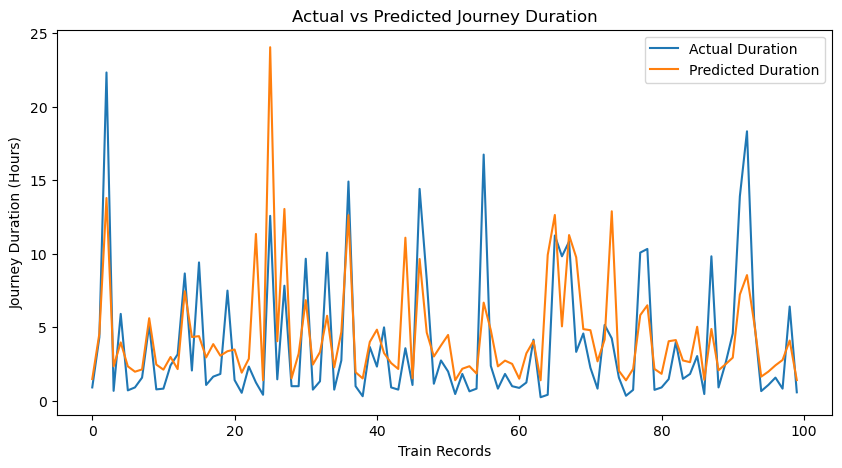

In [49]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.plot(
    y_test.values[:100],
    label="Actual Duration"
)
plt.plot(
    y_pred[:100],
    label="Predicted Duration"
)
plt.title(
    "Actual vs Predicted Journey Duration"
)
plt.xlabel(
    "Train Records"
)
plt.ylabel(
    "Journey Duration (Hours)"
)
plt.legend()
plt.show()

## OUTPUT EXPLANATION :
### ->The graph shows two lines
### ->If both lines are close
### ->The model predictions are accurate.
### ->If lines are far apart
### ->Prediction error is higher.

## FEATURE CO-EFFECIENT ANALYSIS 

### 1. The coefficients generated by the Linear Regression model explain the impact of each input feature on journey duration.
### 2. The positive coefficients indicate that both distance and number of stops increase journey duration.
### 3. The coefficient values help understand the contribution of each feature in the prediction process.
### 4. The intercept represents the base value of journey duration when all input features are zero.

In [50]:
print("Intercept:", model.intercept_)

for feature, coef in zip(x.columns, model.coef_):
    print(feature, ":", coef)

Intercept: 1.1288436759428757
Total_Distance : 0.00465620942150702
Number_of_Stops : 0.11173796305627975


# Project Conclusion

#### 1. This project successfully developed a train journey duration prediction system using Data Science and Machine Learning techniques.
#### 2. The dataset was analyzed, cleaned, and transformed into meaningful features.
#### 3. Exploratory Data Analysis helped identify relationships between distance, stops, and journey duration.
#### 4. A Linear Regression model was developed and evaluated using performance metrics.
#### 5. The final prediction system can estimate train journey duration based on route distance and number of stops.
#### 6. This project demonstrates an end-to-end Data Science workflow:
#####   -> Data preprocessing
#####   -> Data analysis
#####   -> Visualization
#####   -> Machine learning modeling
#####   -> Prediction system implementation